# knob-senses — servidor TCP de dados


## Protocolo

TCP puro, texto, uma amostra por linha terminada em `\n`. **Toda linha tem
exatamente 9 números** separados por vírgula, sem cabeçalho e sem comentário:

```
21.946,1,100.4489,6.033333,0.4010397,79.87427,39.19426,1411.175,0.1623721
```

Essa linha é a saída real da célula 3, não um exemplo inventado.

Do lado do MCU isso é `atof()` direto, sem caso especial. A conexão é de mão
única (servidor → cliente): não há comando de entrada.

## Ordem dos eixos

É a ordem que o modelo aprendeu — **não reordene**:

| # | eixo | # | eixo | # | eixo |
|---|---|---|---|---|---|
| 0 | `temperatura_ambiente` | 3 | `hora_dec` | 6 | `ghit` |
| 1 | `doy` | 4 | `kc` | 7 | `ioeff` |
| 2 | `ghi_cs` | 5 | `angzen` | 8 | `kt` |


## 1. Configuração

Sem argumentos: o que você mudaria na linha de comando é o que se edita aqui.

- `HOST = "0.0.0.0"` aceita conexão de qualquer interface (o ESP32 chega pela
  rede local). Use `"127.0.0.1"` se quiser só a própria máquina.
- `PORT` precisa bater com o que o MCU vai discar.
- `HZ` é a cadência. `1.0` casa com `EI_CLASSIFIER_INTERVAL_MS`. Subir isso só
  serve para testar parser — o loop de 1 Hz da placa não acompanha.


In [2]:
import csv, socket, sys, time
from pathlib import Path
import numpy as np

# ---------------------------------------------------------------------------
# Ordem EXATA dos eixos que src/main.cpp espera em readSample(). O modelo foi
# treinado nesta sequencia: reordenar aqui quebra a inferencia em silencio.
# ---------------------------------------------------------------------------
AXES = (
    "temperatura_ambiente",  # 0
    "doy",                   # 1
    "ghi_cs",                # 2
    "hora_dec",              # 3
    "kc",                    # 4
    "angzen",                # 5
    "ghit",                  # 6
    "ioeff",                 # 7
    "kt",                    # 8
)

HOST = "0.0.0.0"
PORT = 3333
HZ = 1.0

# Um stdout REDIRECIONADO (pipe, arquivo, `jupyter nbconvert --execute`) no
# Windows cai no codepage da locale (cp1252), e ai o travessao do log vira o
# byte 0x97 — que nao e UTF-8 valido. Quem le o pipe com utf-8 quebra no meio.
# Num console interativo ou no Jupyter o Python ja acerta; isto e para o resto.
# O OutStream do Jupyter nao tem reconfigure(), dai o AttributeError no guard.
for _s in (sys.stdout, sys.stderr):
    try:
        _s.reconfigure(encoding="utf-8", errors="replace")
    except (AttributeError, ValueError):
        pass


DATA_DIR = Path.cwd().parent / "data" / "validation"
print(f"dados em {DATA_DIR}", flush=True)

dados em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\validation


## 2. Inventário dos arquivos


In [3]:
def inventario():
    """Lista os CSVs em ordem de leitura, com contagem e colunas faltando."""
    linhas = []
    for path in sorted(DATA_DIR.glob("*.csv")):
        with path.open(newline="", encoding="utf-8-sig") as fh:
            rd = csv.DictReader(fh)
            faltando = [c for c in AXES if c not in (rd.fieldnames or [])]
            n = sum(1 for _ in rd)
        linhas.append((path.name, n, faltando))
    return linhas


_total = 0
for _nome, _n, _falta in inventario():
    _total += _n
    _aviso = f"   FALTANDO: {_falta}" if _falta else ""
    print(f"{_nome:22} {_n:>7} amostras{_aviso}", flush=True)

print(f"{'total':22} {_total:>7} amostras", flush=True)

ifpec1_2024.csv          46514 amostras
ifpec2_2024.csv          46514 amostras
ifpee1_2024.csv          46514 amostras
ifpee3_2024.csv          46514 amostras
total                   186056 amostras


In [4]:
def load_samples():
    DATA_LINE = ("PCA", *AXES)
    """Uma amostra (tupla de 9 floats) por vez, percorrendo os CSVs em ordem."""
    for path in sorted([DATA_DIR / "ifpee3_2024.csv"]):
        with path.open(newline="", encoding="utf-8-sig") as fh:
            for row in csv.DictReader(fh):
                if row['PCA'] and float(row["PCA"]) > 0:
                    yield tuple(float(row[c]) for c in DATA_LINE)

def get_sample_bytes(sample: tuple):
    return np.array(sample[1:], dtype=np.float32).tobytes()

raw_samples = list(load_samples())

sample_bytes = [ get_sample_bytes(amostra) for amostra in raw_samples]

[np.frombuffer(sample, dtype=np.float32) for sample in sample_bytes[0:3]]  # DEBUG: mostra as 3 primeiras amostras

[array([2.1945999e+01, 1.0000000e+00, 1.0044891e+02, 6.0333333e+00,
        4.0103966e-01, 7.9874275e+01, 3.9194260e+01, 1.4111747e+03,
        1.6237207e-01], dtype=float32),
 array([2.1938000e+01, 1.0000000e+00, 1.1997434e+02, 6.1166668e+00,
        3.5519260e-01, 7.8728027e+01, 4.1490761e+01, 1.4111747e+03,
        1.5448959e-01], dtype=float32),
 array([2.1924000e+01, 1.0000000e+00, 1.4015808e+02, 6.1999998e+00,
        2.4780591e-01, 7.7581047e+01, 3.3938793e+01, 1.4111747e+03,
        1.1444388e-01], dtype=float32)]

In [5]:
errors = list()
def reply(conn: socket.socket, index: int, samples=sample_bytes):
    conn.setsockopt(socket.IPPROTO_TCP, socket.TCP_NODELAY, 1)
    with conn:
        conn.sendall(samples[index])
        if conn.recv(1) != b"\x01":
            print(f"erro no ack do sample {index}", flush=True)
        elif conn.recv(1) == b"\x02":
            pred = conn.recv(4)
            # calcula o erro do valor previsto em relacao ao valor real
            pred_value = np.frombuffer(pred, dtype=np.float32)[0]
            real = raw_samples[index + 1][0]
            abs_err = np.abs(pred_value - real)
            errors.append(abs_err)
            mae_err = np.array(errors).mean()
            print(f"sample {index + 1}: real={real:.4f}, pred={pred_value:.4f}, err={abs_err:.4f}, mae={mae_err:.4f}", flush=True)
            return (index + 1, real, pred_value, abs_err, mae_err)
        return tuple()


In [ ]:
# ---------------------------------------------------------------------------
# A CELULA BLOQUEANTE. Ela NAO RETORNA: o kernel fica aqui servindo ate voce
# apertar o stop (ou Ctrl-C). Depois disso as celulas acima continuam
# disponiveis para reinspecionar os dados.
# ---------------------------------------------------------------------------
srv = socket.socket(socket.AF_INET, socket.SOCK_STREAM)

# SO_EXCLUSIVEADDRUSE no Windows, e NAO SO_REUSEADDR. Medido nesta maquina:
#   - com SO_REUSEADDR, um segundo processo consegue fazer bind na porta de
#     um socket que ja esta escutando, em silencio: viram dois servidores na
#     mesma porta e cada cliente cai em um.
#   - SO_EXCLUSIVEADDRUSE bloqueia isso (WSAEADDRINUSE) e, medido tambem,
#     ainda permite reabrir logo apos um cliente desconectar (TIME_WAIT).
# Nos outros sistemas SO_REUSEADDR e o certo: la ele NAO permite sequestro,
# e e ele que evita o TIME_WAIT.
_exclusivo = getattr(socket, "SO_EXCLUSIVEADDRUSE", None)
if _exclusivo is not None:
    srv.setsockopt(socket.SOL_SOCKET, _exclusivo, 1)
else:
    srv.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)

try:
    srv.bind((HOST, PORT))            # erro de porta estoura AQUI, na celula
    srv.listen(1)
except OSError:
    srv.close()
    raise

# Timeout no listen so para o accept() VOLTAR ao bytecode a cada 0,5 s. Sem
# isso o botao de stop nao funciona: com o accept() bloqueado, o
# KeyboardInterrupt fica pendente e so seria levantado quando chegasse um
# cliente — ou seja, nunca, que e justamente o estado ocioso do servidor.
srv.settimeout(5)

print(f"Server started at {HOST}:{PORT}", flush=True)

try:
    index = 0
    with open(Path.cwd() / 'model_eval.csv', "w") as model_eval_log:
        model_eval_log.write("sample,real,pred,err,mae\n")
        while True:
            try:
                try:
                    conn, addr = srv.accept()
                except socket.timeout:
                    pass
                else:
                    if result := reply(conn, index):
                        model_eval_log.write(",".join(result) + "\n")
            except OSError:
                pass
            else:
                index += 1                          # cliente desconectou no meio
except KeyboardInterrupt:
    print("\ninterrupted", flush=True)
finally:
    srv.close()
    print("socket closed", flush=True)

Server started at 0.0.0.0:3333
socket closed


UnsupportedOperation: not writable

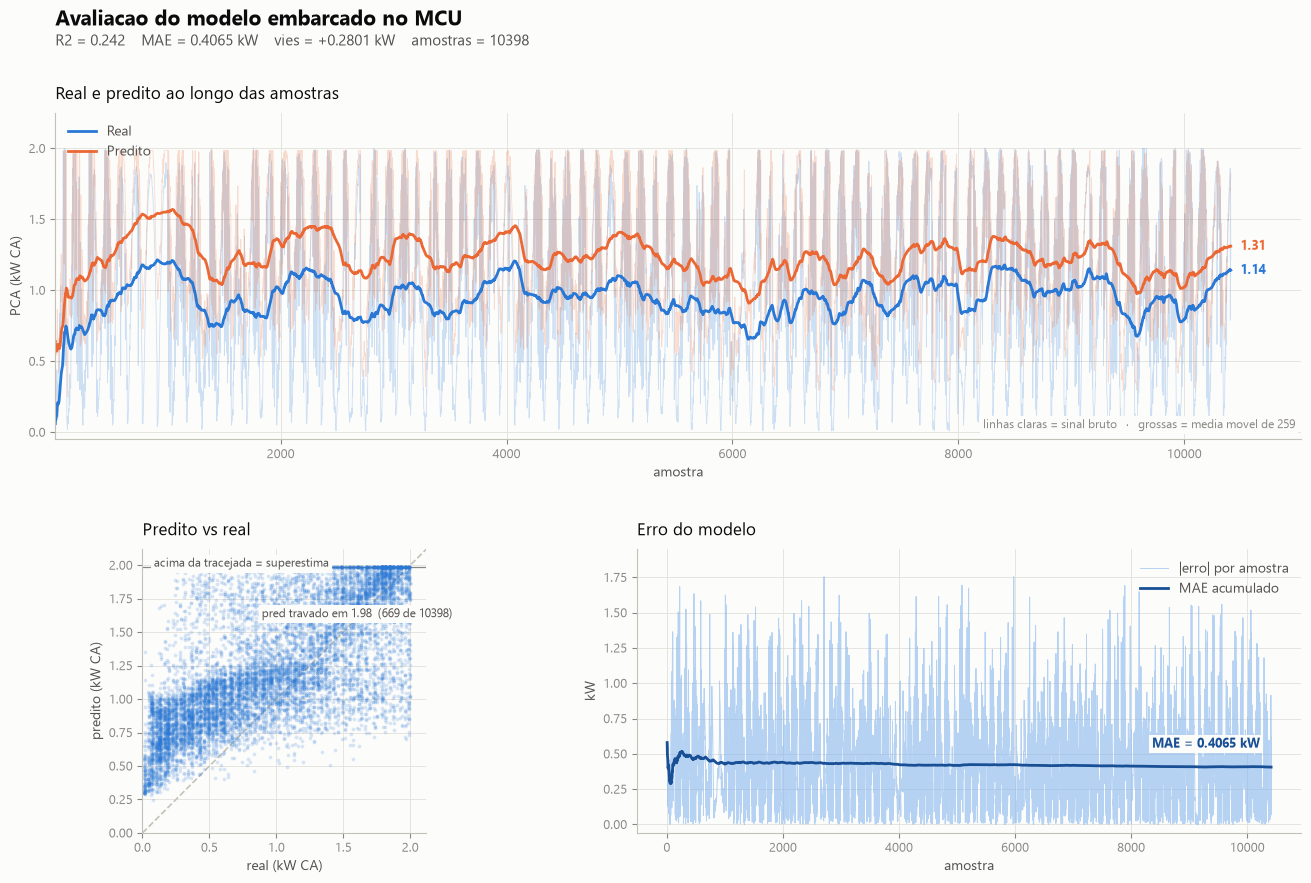

In [9]:
# ---------------------------------------------------------------------------
# Avaliacao do modelo embarcado: o MCU recebeu uma amostra por vez por TCP e
# devolveu a predicao. Este e o desempenho REAL em campo -- medido, nao
# estimado. A metrica offline do treino nao passa por aqui.
#
# COMO LER: no painel "Predito vs real" a nuvem fica ACIMA da tracejada (o
# modelo superestima) e forma uma linha dura no topo (o predito travou no
# teto). Os tres numeros do cabecalho resumem isso.
#
# CORES: par categorico validado para Real/Predito (dE CVD 24,7) e os degraus
# 250 e 600 da rampa azul no painel de erro, que e uma relacao ORDINAL (erro
# por amostra -> MAE acumulado: mesma grandeza em dois niveis de agregacao).
# Superficie #fcfcfb, grade hairline SOLIDA (tracejado le como limiar), sem
# eixo duplo -- tudo em kW.
#
# A versao em tabela deste grafico e o proprio model_eval.csv.
# ---------------------------------------------------------------------------
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path

SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})

df_eval = pd.read_csv(Path.cwd() / "model_eval.csv")

# Media movel proporcional ao tamanho: com 10 mil amostras o sinal bruto
# esconde o vies, que e justamente o que precisa aparecer.
janela = max(1, len(df_eval) // 40)
x = df_eval["sample"].to_numpy()
real_l = df_eval["real"].rolling(janela, min_periods=1).mean()
pred_l = df_eval["pred"].rolling(janela, min_periods=1).mean()

r2   = 1 - ((df_eval["real"] - df_eval["pred"]) ** 2).sum() / ((df_eval["real"] - df_eval["real"].mean()) ** 2).sum()
mae  = df_eval["err"].mean()
vies = (df_eval["pred"] - df_eval["real"]).mean()
teto = df_eval["pred"].max()
no_teto = int((df_eval["pred"] >= teto - 0.01).sum())

fig = plt.figure(figsize=(14, 9))
gs = GridSpec(2, 2, figure=fig, height_ratios=[1.15, 1.0], width_ratios=[1.0, 1.45],
              hspace=0.36, wspace=0.22)
HALO = dict(facecolor=SUPERFICIE, edgecolor="none", pad=2.0)


def enfeitar(ax, titulo, xlabel, ylabel):
    ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
    ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
    ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
    ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")   # solida, nunca tracejada
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(EIXO)
    ax.tick_params(colors=MUDO, labelsize=9)


# --- 1. real vs predito ao longo das amostras ------------------------------
ax = fig.add_subplot(gs[0, :])
ax.plot(x, df_eval["real"], color=REAL, lw=0.6, alpha=0.22)
ax.plot(x, df_eval["pred"], color=PREDITO, lw=0.6, alpha=0.22)
ax.plot(x, real_l, color=REAL, lw=2.0, label="Real")
ax.plot(x, pred_l, color=PREDITO, lw=2.0, label="Predito")
enfeitar(ax, "Real e predito ao longo das amostras", "amostra", "PCA (kW CA)")
ax.set_xlim(x[0], x[-1] + (x[-1] - x[0]) * 0.06)
ax.set_ylim(-0.05, 2.25)
for serie, cor in ((real_l, REAL), (pred_l, PREDITO)):
    ax.annotate(f"{serie.iloc[-1]:.2f}", (x[-1], serie.iloc[-1]), xytext=(7, 0),
                textcoords="offset points", color=cor, fontsize=9,
                va="center", fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2)
ax.text(0.995, 0.025, f"linhas claras = sinal bruto   ·   grossas = media movel de {janela}",
        transform=ax.transAxes, ha="right", va="bottom", color=MUDO,
        fontsize=8.5, bbox=HALO)

# --- 2. predito vs real -- o painel que diagnostica ------------------------
ax = fig.add_subplot(gs[1, 0])
lim = (0, max(df_eval["real"].max(), df_eval["pred"].max()) * 1.06)
ax.plot(lim, lim, color=EIXO, lw=1.2, linestyle="--", zorder=1)   # identidade = limiar
ax.axhline(teto, color=MUDO, lw=0.9, zorder=1)
ax.scatter(df_eval["real"], df_eval["pred"], s=7, color=REAL,
           alpha=0.18, linewidths=0, zorder=2)
ax.annotate(f"pred travado em {teto:.2f}  ({no_teto} de {len(df_eval)})",
            (lim[1] * 0.42, teto), xytext=(0, -36), textcoords="offset points",
            color=TINTA_2, fontsize=8.5, bbox=HALO)
ax.text(lim[1] * 0.04, lim[1] * 0.97, "acima da tracejada = superestima",
        color=TINTA_2, fontsize=8.5, va="top", bbox=HALO)
ax.set_aspect("equal")
ax.set_xlim(lim)
ax.set_ylim(lim)
enfeitar(ax, "Predito vs real", "real (kW CA)", "predito (kW CA)")

# --- 3. erro absoluto e MAE acumulado --------------------------------------
ax = fig.add_subplot(gs[1, 1])
ax.plot(x, df_eval["err"], color=ERRO_CLARO, lw=0.7, alpha=0.6, label="|erro| por amostra")
ax.plot(x, df_eval["mae"], color=MAE_ESC, lw=2.0, label="MAE acumulado")
enfeitar(ax, "Erro do modelo", "amostra", "kW")
ax.set_ylim(-0.06, 1.95)
ax.annotate(f"MAE = {mae:.4f} kW", (x[-1], df_eval["mae"].iloc[-1]), xytext=(-8, 14),
            textcoords="offset points", ha="right", color=MAE_ESC, fontsize=9,
            fontweight="bold", bbox=HALO)
ax.legend(frameon=False, loc="upper right", fontsize=10, labelcolor=TINTA_2)

fig.suptitle("Avaliacao do modelo embarcado no MCU", color=TINTA, fontsize=15,
             x=0.07, ha="left", y=0.985, fontweight="bold")
fig.text(0.07, 0.945,
         f"R2 = {r2:.3f}    MAE = {mae:.4f} kW    vies = {vies:+.4f} kW    amostras = {len(df_eval)}",
         color=TINTA_2, fontsize=11, ha="left")
fig.subplots_adjust(top=0.87, bottom=0.07, left=0.07, right=0.96)
plt.show()
